# Física III — Eletromagnetismo

### Material de estudo visual — Engenharia Naval, Poli-USP

Este notebook é um guia de **revisão visual** para toda a disciplina de Física III (eletromagnetismo clássico). Não é uma lista de exercícios — é um "livro vivo": cada conceito importante vem acompanhado de um gráfico, uma animação ou um diagrama que mostra o que ele significa fisicamente.

Rode as células em ordem (a primeira configura o ambiente). Sinta-se livre para mudar os parâmetros (cargas, correntes, dimensões) e observar como os gráficos e animações mudam — essa é a melhor forma de construir intuição física para campos vetoriais, que são o coração desta disciplina.

## Sumário

### Parte I — Eletrostática e Circuitos de Corrente Contínua
1. [Carga elétrica e campo elétrico](#sec1)
2. [Lei de Gauss](#sec2)
3. [Potencial elétrico](#sec3)
4. [Capacitância](#sec4)
5. [Corrente, resistência e força eletromotriz](#sec5)

### Parte II — Magnetismo e Ondas Eletromagnéticas
6. [Campo magnético e forças magnéticas](#sec6)
7. [Fontes de campo magnético](#sec7)
8. [Indução eletromagnética e corrente de deslocamento](#sec8)
9. [Indutância](#sec9)
10. [Ondas eletromagnéticas](#sec10)


## Configuração inicial

Rode esta célula primeiro. Ela importa tudo que vamos usar e define um estilo visual consistente (grid leve, paleta de cores agradável) para todos os gráficos do notebook. Como não temos `scipy`, `plotly` nem `ipywidgets`, tudo é feito "na mão" com `numpy`, `matplotlib` e `sympy`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import FancyArrowPatch, Circle, Arc, Rectangle, Wedge
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import HTML
import sympy as sp

plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "font.size": 11,
    "lines.linewidth": 2.2,
    "axes.prop_cycle": plt.cycler(color=[
        "#1f77b4", "#d62728", "#2ca02c", "#9467bd",
        "#ff7f0e", "#17becf", "#8c564b", "#e377c2",
    ]),
})

COR_DESTAQUE = "#d62728"
COR_OK = "#2ca02c"
COR_AZUL = "#1f77b4"
COR_ROXO = "#9467bd"
COR_LARANJA = "#ff7f0e"
COR_CIANO = "#17becf"

# Constantes físicas (SI)
k_coulomb = 8.9875e9      # N m^2 / C^2
eps0 = 8.8542e-12         # F/m
mu0 = 4 * np.pi * 1e-7    # T m / A
c_luz = 1 / np.sqrt(mu0 * eps0)

print("Setup concluído: numpy, matplotlib, sympy prontos.")
print(f"c = 1/sqrt(mu0 eps0) = {c_luz:.4e} m/s")


Setup concluído: numpy, matplotlib, sympy prontos.
c = 1/sqrt(mu0 eps0) = 2.9979e+08 m/s


## Parte I — Eletrostática e Circuitos de Corrente Contínua

<a id="sec1"></a>
## 1. Carga elétrica e campo elétrico

A **lei de Coulomb** descreve a força entre duas cargas puntiformes $q_1$ e $q_2$ separadas por uma distância $r$:

$$F = k\frac{q_1 q_2}{r^2}, \qquad k = \frac{1}{4\pi\varepsilon_0} \approx 8{,}99\times10^9\ \text{N·m}^2/\text{C}^2$$

Cargas de mesmo sinal se repelem, cargas de sinais opostos se atraem. Em vez de pensar em ação à distância, é mais produtivo (e é assim que o resto do curso é construído) imaginar que toda carga cria um **campo elétrico** $\vec E$ no espaço ao seu redor, e que uma segunda carga apenas "sente" esse campo local:

$$\vec E(\vec r) = \frac{1}{4\pi\varepsilon_0}\frac{q}{r^2}\hat r, \qquad \vec F = q_0 \vec E$$

> **Intuição física:** as linhas de campo são um mapa visual de $\vec E$ — elas apontam na direção da força que uma carga de prova positiva sentiria, e sua densidade (quão "apertadas" estão) indica a intensidade do campo. Cargas positivas são "fontes" (linhas divergem), cargas negativas são "sumidouros" (linhas convergem).

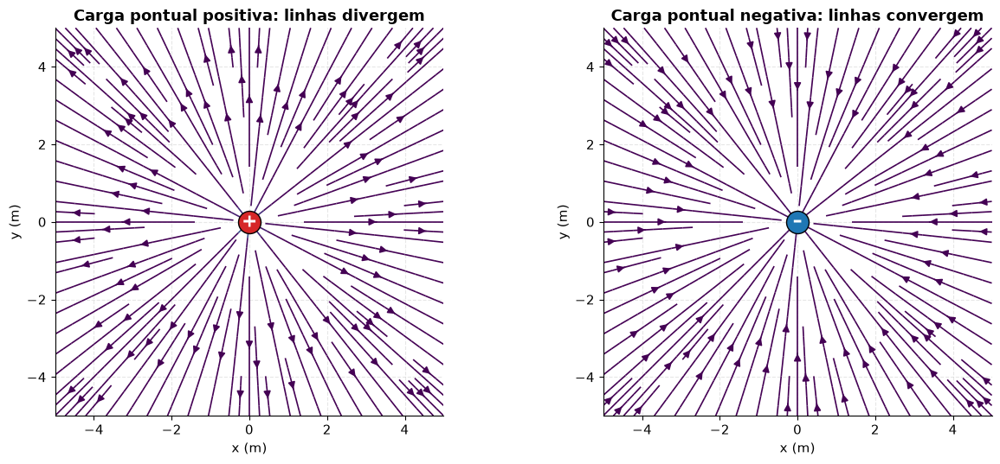

In [2]:
def campo_cargas_pontuais(X, Y, cargas):
    # cargas: lista de (q, x0, y0). Retorna Ex, Ey.
    Ex = np.zeros_like(X)
    Ey = np.zeros_like(Y)
    for q, x0, y0 in cargas:
        dx, dy = X - x0, Y - y0
        r3 = (dx**2 + dy**2 + 0.05**2) ** 1.5  # amortecimento para evitar divergência numérica
        Ex += k_coulomb * q * dx / r3
        Ey += k_coulomb * q * dy / r3
    return Ex, Ey

x = np.linspace(-5, 5, 220)
y = np.linspace(-5, 5, 220)
X, Y = np.meshgrid(x, y)

fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, q_sign, titulo, cor in zip(axs, [+1e-9, -1e-9],
                                    ["Carga pontual positiva: linhas divergem",
                                     "Carga pontual negativa: linhas convergem"],
                                    [COR_DESTAQUE, COR_AZUL]):
    Ex, Ey = campo_cargas_pontuais(X, Y, [(q_sign, 0, 0)])
    Emag = np.hypot(Ex, Ey)
    ax.streamplot(X, Y, Ex, Ey, color=Emag, cmap="viridis", density=1.3,
                  linewidth=1.2, arrowsize=1.2)
    marcador = "+" if q_sign > 0 else "–"
    ax.scatter([0], [0], s=350, color=cor, edgecolor="k", zorder=5)
    ax.text(0, 0, marcador, color="white", ha="center", va="center",
            fontsize=16, fontweight="bold", zorder=6)
    ax.set_title(titulo)
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()


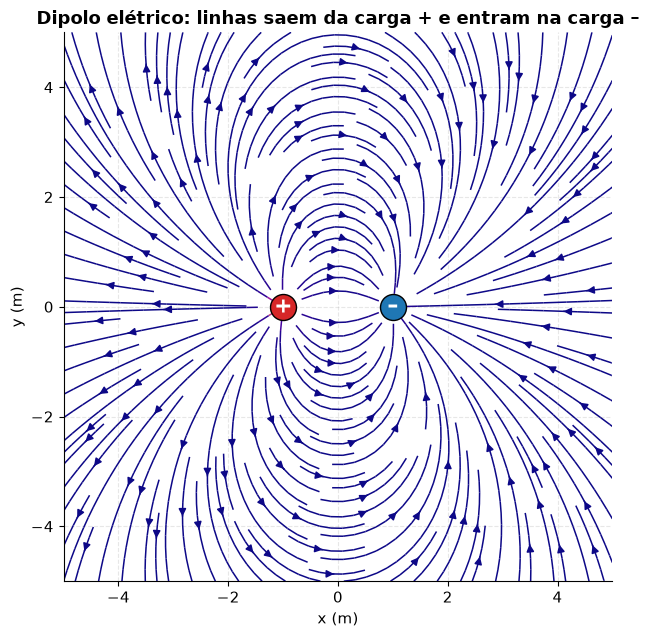

In [3]:
# Dipolo elétrico: duas cargas opostas
fig, ax = plt.subplots(figsize=(7, 6.5))
cargas_dipolo = [(1e-9, -1.0, 0.0), (-1e-9, 1.0, 0.0)]
Ex, Ey = campo_cargas_pontuais(X, Y, cargas_dipolo)
Emag = np.hypot(Ex, Ey)

ax.streamplot(X, Y, Ex, Ey, color=Emag, cmap="plasma", density=1.6,
              linewidth=1.1, arrowsize=1.1)
ax.scatter([-1], [0], s=350, color=COR_DESTAQUE, edgecolor="k", zorder=5)
ax.text(-1, 0, "+", color="white", ha="center", va="center", fontsize=16, fontweight="bold", zorder=6)
ax.scatter([1], [0], s=350, color=COR_AZUL, edgecolor="k", zorder=5)
ax.text(1, 0, "–", color="white", ha="center", va="center", fontsize=16, fontweight="bold", zorder=6)
ax.set_title("Dipolo elétrico: linhas saem da carga + e entram na carga –")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
ax.set_xlim(-5, 5); ax.set_ylim(-5, 5)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


> **Intuição física:** perto de cada carga do dipolo o campo parece o de uma carga isolada (linhas quase radiais). Longe do dipolo, as linhas "sabem" que as cargas se cancelam em parte e o campo cai mais rápido com a distância ($\propto 1/r^3$ em vez de $1/r^2$) — esse é o campo típico de moléculas polares, por exemplo.

<a id="sec2"></a>
## 2. Lei de Gauss

O **fluxo elétrico** através de uma superfície mede "quantas linhas de campo" atravessam essa superfície:

$$\Phi_E = \oint \vec E\cdot d\vec A$$

A **lei de Gauss** afirma que o fluxo através de qualquer superfície fechada depende apenas da carga líquida envolvida por ela:

$$\Phi_E = \oint \vec E\cdot d\vec A = \frac{q_{\text{env}}}{\varepsilon_0}$$

Isso é extremamente poderoso: para distribuições de carga com simetria (esférica, cilíndrica, planar), podemos escolher uma "superfície gaussiana" conveniente e calcular $E$ sem integrais complicadas — basta contar quantas linhas atravessam a superfície.

> **Intuição física:** pense no fluxo como a "vazão de água" através de uma rede de pesca mergulhada no campo. Se não há fontes (cargas) dentro da rede, tudo que entra sai — fluxo líquido zero. Se há uma fonte dentro, o fluxo líquido é proporcional à carga daquela fonte, não importa o formato da rede.

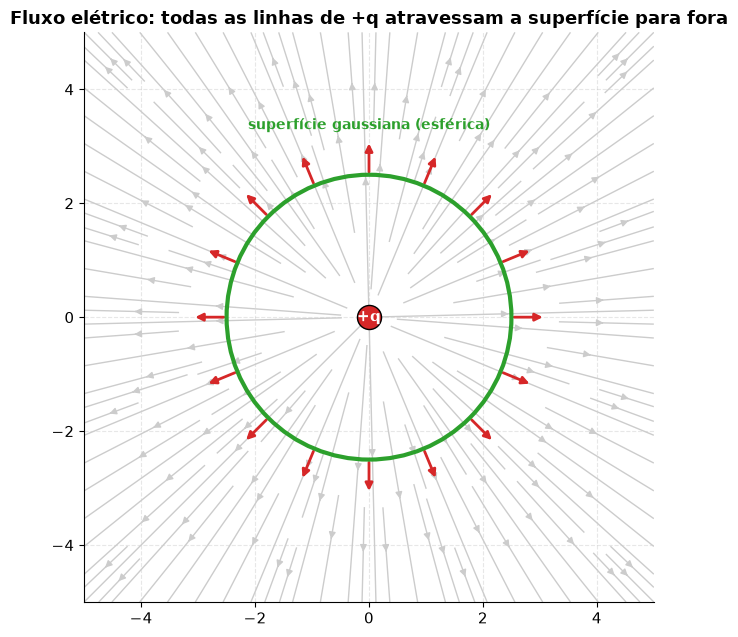

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
q_central = 1e-9
Ex, Ey = campo_cargas_pontuais(X, Y, [(q_central, 0, 0)])
Emag = np.hypot(Ex, Ey)
ax.streamplot(X, Y, Ex, Ey, color="#cccccc", density=1.4, linewidth=1.0, arrowsize=1.0)

# Superfície gaussiana esférica (círculo em 2D)
R_gauss = 2.5
circ = Circle((0, 0), R_gauss, fill=False, edgecolor=COR_OK, linewidth=3, linestyle="-", zorder=5)
ax.add_patch(circ)

# Vetores de área (normais) amostrados ao longo da superfície, mostrando E atravessando-a
thetas = np.linspace(0, 2 * np.pi, 16, endpoint=False)
for th in thetas:
    xp, yp = R_gauss * np.cos(th), R_gauss * np.sin(th)
    Exp, Eyp = campo_cargas_pontuais(np.array([[xp]]), np.array([[yp]]), [(q_central, 0, 0)])
    norm = np.hypot(Exp[0, 0], Eyp[0, 0])
    ux, uy = Exp[0, 0] / norm, Eyp[0, 0] / norm
    ax.annotate("", xy=(xp + 0.6 * ux, yp + 0.6 * uy), xytext=(xp, yp),
                arrowprops=dict(arrowstyle="-|>", color=COR_DESTAQUE, lw=2))

ax.scatter([0], [0], s=300, color=COR_DESTAQUE, edgecolor="k", zorder=6)
ax.text(0, 0, "+q", color="white", ha="center", va="center", fontsize=11, fontweight="bold", zorder=7)
ax.text(0, R_gauss + 0.8, "superfície gaussiana (esférica)", color=COR_OK, ha="center", fontsize=10, fontweight="bold")
ax.set_title(r"Fluxo elétrico: todas as linhas de +q atravessam a superfície para fora")
ax.set_xlim(-5, 5); ax.set_ylim(-5, 5)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


### Exemplo clássico: casca esférica condutora carregada

Para uma casca esférica fina de raio $R$ com carga total $Q$, a simetria esférica permite usar uma superfície gaussiana concêntrica de raio $r$:

$$E(r) = \begin{cases} 0, & r < R \quad \text{(nenhuma carga envolvida)}\\[4pt] \dfrac{1}{4\pi\varepsilon_0}\dfrac{Q}{r^2}, & r > R \quad \text{(toda a carga envolvida, como se fosse pontual)} \end{cases}$$

Repare na **descontinuidade visual**: dentro da casca o campo é identicamente nulo; fora, ele se comporta exatamente como o de uma carga pontual $Q$ no centro.

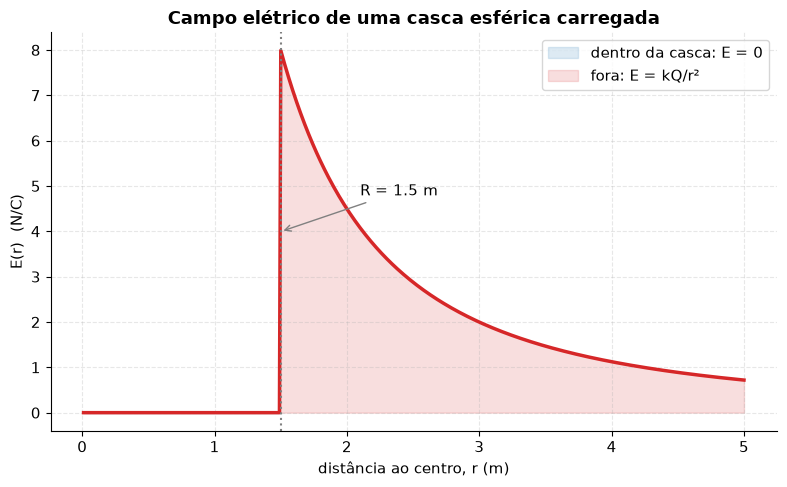

In [5]:
R_casca = 1.5
Q_casca = 2e-9
r_vals = np.linspace(0.01, 5, 500)
E_vals = np.where(r_vals < R_casca, 0.0, k_coulomb * Q_casca / r_vals**2)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(r_vals, E_vals, color=COR_DESTAQUE, linewidth=2.5)
ax.axvline(R_casca, color="gray", linestyle=":", linewidth=1.5)
ax.text(R_casca, ax.get_ylim()[1] * 0.0, "", visible=False)
ax.fill_between(r_vals, 0, E_vals, where=(r_vals < R_casca), color=COR_AZUL, alpha=0.15, label="dentro da casca: E = 0")
ax.fill_between(r_vals, 0, E_vals, where=(r_vals >= R_casca), color=COR_DESTAQUE, alpha=0.15, label="fora: E = kQ/r²")
ax.annotate(f"R = {R_casca} m", xy=(R_casca, max(E_vals) * 0.5), xytext=(R_casca + 0.6, max(E_vals) * 0.6),
            arrowprops=dict(arrowstyle="->", color="gray"))
ax.set_xlabel("distância ao centro, r (m)")
ax.set_ylabel("E(r)  (N/C)")
ax.set_title("Campo elétrico de uma casca esférica carregada")
ax.legend()
plt.tight_layout()
plt.show()


<a id="sec3"></a>
## 3. Potencial elétrico

O **potencial elétrico** $V$ é a energia potencial elétrica por unidade de carga. Ele se relaciona com o campo por

$$V(\vec r) = -\int_{\text{ref}}^{\vec r} \vec E\cdot d\vec l, \qquad \vec E = -\nabla V$$

Para uma carga puntiforme (com referência $V=0$ no infinito):

$$V(r) = \frac{1}{4\pi\varepsilon_0}\frac{q}{r}$$

As **superfícies equipotenciais** (onde $V$ é constante) têm uma propriedade geométrica fundamental: elas são **sempre perpendiculares** às linhas de campo elétrico, pois $\vec E = -\nabla V$ aponta na direção de máxima variação de $V$.

> **Intuição física:** pense no potencial como "altitude" num mapa topográfico e no campo elétrico como a direção que uma bola rolaria (descendo a encosta mais íngreme). As curvas de nível (equipotenciais) nunca cruzam a direção de maior declive — por isso campo e equipotenciais são sempre ortogonais.

C:\Users\PedroOliveira\AppData\Local\Temp\ipykernel_22820\1665917404.py:33: UserWarning: Glyph 10178 (\N{PERPENDICULAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


C:\Users\PedroOliveira\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10178 (\N{PERPENDICULAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


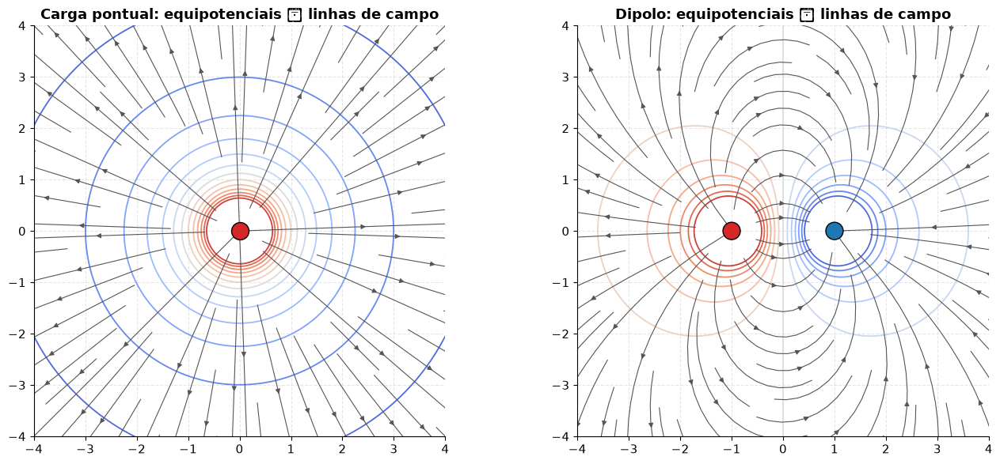

In [6]:
def potencial_cargas_pontuais(X, Y, cargas):
    V = np.zeros_like(X)
    for q, x0, y0 in cargas:
        r = np.sqrt((X - x0)**2 + (Y - y0)**2 + 0.05**2)
        V += k_coulomb * q / r
    return V

fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# --- carga única ---
ax = axs[0]
V = potencial_cargas_pontuais(X, Y, [(1e-9, 0, 0)])
Ex, Ey = campo_cargas_pontuais(X, Y, [(1e-9, 0, 0)])
Vclip = np.clip(V, -15, 15)
cs = ax.contour(X, Y, Vclip, levels=14, cmap="coolwarm", linewidths=1.3)
ax.streamplot(X, Y, Ex, Ey, color="#555555", density=1.0, linewidth=0.8, arrowsize=0.9)
ax.scatter([0], [0], s=250, color=COR_DESTAQUE, edgecolor="k", zorder=6)
ax.set_title("Carga pontual: equipotenciais ⟂ linhas de campo")
ax.set_aspect("equal"); ax.set_xlim(-4, 4); ax.set_ylim(-4, 4)

# --- dipolo ---
ax = axs[1]
cargas_dipolo = [(1e-9, -1.0, 0.0), (-1e-9, 1.0, 0.0)]
V = potencial_cargas_pontuais(X, Y, cargas_dipolo)
Ex, Ey = campo_cargas_pontuais(X, Y, cargas_dipolo)
Vclip = np.clip(V, -10, 10)
cs = ax.contour(X, Y, Vclip, levels=16, cmap="coolwarm", linewidths=1.3)
ax.streamplot(X, Y, Ex, Ey, color="#555555", density=1.0, linewidth=0.8, arrowsize=0.9)
ax.scatter([-1, 1], [0, 0], s=250, color=[COR_DESTAQUE, COR_AZUL], edgecolor="k", zorder=6)
ax.set_title("Dipolo: equipotenciais ⟂ linhas de campo")
ax.set_aspect("equal"); ax.set_xlim(-4, 4); ax.set_ylim(-4, 4)

plt.tight_layout()
plt.show()


<a id="sec4"></a>
## 4. Capacitância

Um **capacitor** armazena energia elétrica separando cargas opostas em dois condutores. Para um capacitor de placas paralelas de área $A$ separadas por distância $d$:

$$C = \frac{\varepsilon_0 A}{d}, \qquad Q = CV$$

Entre as placas (longe das bordas) o campo é praticamente **uniforme**, perpendicular às placas. A energia armazenada é

$$U = \frac{1}{2}CV^2 = \frac{Q^2}{2C} = \frac{1}{2}QV$$

> **Intuição física:** quanto maior a área das placas ou menor a separação entre elas, mais carga o capacitor armazena para a mesma diferença de potencial — ele "cabe mais carga" porque as cargas opostas se atraem fortemente através do gap estreito.

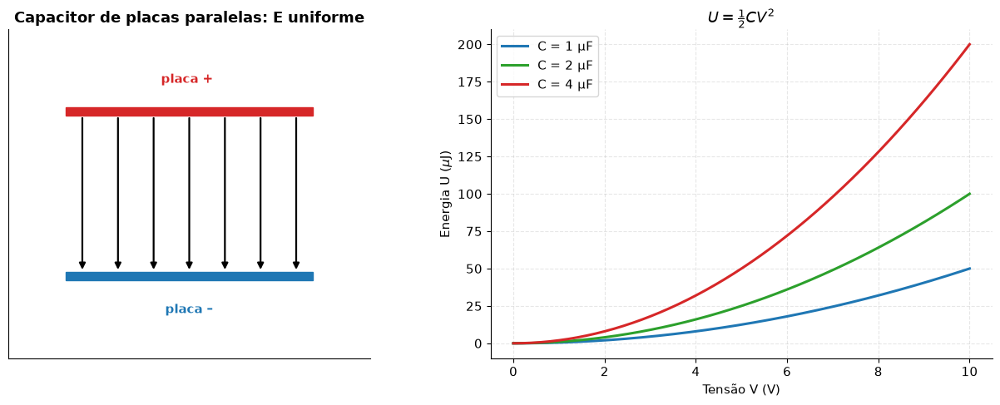

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5))

# --- Campo uniforme entre placas ---
ax = axs[0]
d_placas = 2.0
largura = 3.0
ax.add_patch(Rectangle((-largura/2, d_placas/2 - 0.05), largura, 0.1, color=COR_DESTAQUE, zorder=5))
ax.add_patch(Rectangle((-largura/2, -d_placas/2 - 0.05), largura, 0.1, color=COR_AZUL, zorder=5))
ax.text(0, d_placas/2 + 0.35, "placa + ", color=COR_DESTAQUE, ha="center", fontweight="bold")
ax.text(0, -d_placas/2 - 0.45, "placa –", color=COR_AZUL, ha="center", fontweight="bold")

xs_campo = np.linspace(-largura/2 + 0.2, largura/2 - 0.2, 7)
for xp in xs_campo:
    ax.annotate("", xy=(xp, -d_placas/2 + 0.05), xytext=(xp, d_placas/2 - 0.05),
                arrowprops=dict(arrowstyle="-|>", color="k", lw=1.6))
ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2, 2)
ax.set_aspect("equal")
ax.set_title("Capacitor de placas paralelas: E uniforme")
ax.set_xticks([]); ax.set_yticks([])

# --- Energia armazenada ---
ax = axs[1]
V_range = np.linspace(0, 10, 200)
for Ccap, cor in zip([1e-6, 2e-6, 4e-6], [COR_AZUL, COR_OK, COR_DESTAQUE]):
    U = 0.5 * Ccap * V_range**2
    ax.plot(V_range, U * 1e6, color=cor, label=f"C = {Ccap*1e6:.0f} µF")
ax.set_xlabel("Tensão V (V)")
ax.set_ylabel(r"Energia U ($\mu$J)")
ax.set_title(r"$U = \frac{1}{2}CV^2$")
ax.legend()

plt.tight_layout()
plt.show()


### Carga e descarga de um capacitor (circuito RC)

Ao carregar um capacitor através de um resistor $R$ com uma bateria $V_0$, a tensão no capacitor evolui como

$$V_{\text{carga}}(t) = V_0\left(1 - e^{-t/RC}\right)$$

e ao descarregar (sem a bateria, apenas pelo resistor):

$$V_{\text{descarga}}(t) = V_0\, e^{-t/RC}$$

A constante de tempo $\tau = RC$ determina a "velocidade" do processo: após $t=\tau$, o capacitor já atingiu ${\approx}63\%$ da carga final (ou perdeu ${\approx}63\%$ dela, na descarga).

In [8]:
V0 = 10.0
R_rc = 1000.0
C_rc = 1e-3
tau = R_rc * C_rc
t_max = 5 * tau
t_arr = np.linspace(0, t_max, 55)
V_carga = V0 * (1 - np.exp(-t_arr / tau))
V_descarga = V0 * np.exp(-t_arr / tau)

fig, axs = plt.subplots(1, 2, figsize=(12, 5), dpi=75)
line_c, = axs[0].plot([], [], color=COR_DESTAQUE, lw=2.5)
pt_c, = axs[0].plot([], [], "o", color=COR_DESTAQUE, ms=9)
axs[0].set_xlim(0, t_max); axs[0].set_ylim(0, V0 * 1.1)
axs[0].axhline(V0, color="gray", linestyle=":", lw=1)
axs[0].axvline(tau, color="gray", linestyle=":", lw=1)
axs[0].text(tau, 0.3, r"$\tau=RC$", color="gray")
axs[0].set_title("Carga do capacitor")
axs[0].set_xlabel("t (s)"); axs[0].set_ylabel("V(t) (V)")

bar_c = axs[1].bar([0], [0], width=0.6, color=COR_DESTAQUE)
axs[1].set_xlim(-1, 1); axs[1].set_ylim(0, V0 * 1.1)
axs[1].set_xticks([]); axs[1].set_title("Nível de carga (barra)")
axs[1].set_ylabel("V(t) (V)")

def init():
    line_c.set_data([], [])
    pt_c.set_data([], [])
    bar_c[0].set_height(0)
    return line_c, pt_c, bar_c[0]

def animar(i):
    line_c.set_data(t_arr[:i+1], V_carga[:i+1])
    pt_c.set_data([t_arr[i]], [V_carga[i]])
    bar_c[0].set_height(V_carga[i])
    return line_c, pt_c, bar_c[0]

anim_rc = animation.FuncAnimation(fig, animar, init_func=init, frames=len(t_arr),
                                   interval=30, blit=True)
plt.tight_layout()
plt.close(fig)
HTML(anim_rc.to_jshtml())


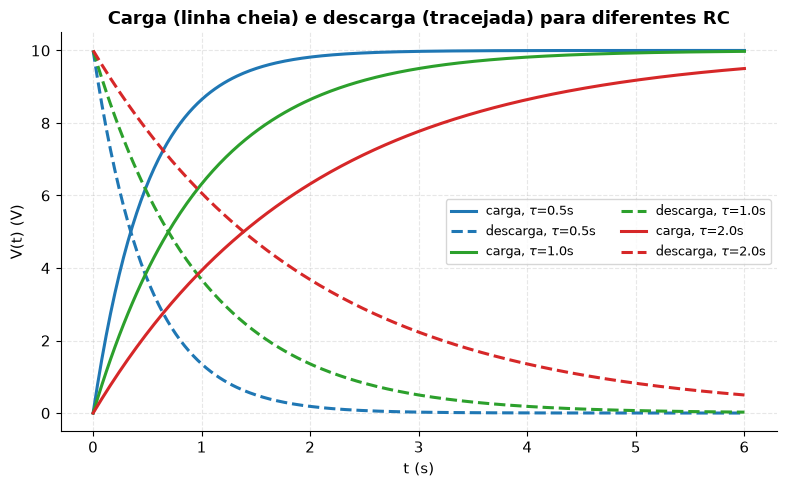

In [9]:
# Comparação: carga e descarga para diferentes constantes de tempo RC
fig, ax = plt.subplots(figsize=(8, 5))
for tau_i, cor in zip([0.5, 1.0, 2.0], [COR_AZUL, COR_OK, COR_DESTAQUE]):
    t_i = np.linspace(0, 6, 300)
    ax.plot(t_i, V0 * (1 - np.exp(-t_i / tau_i)), color=cor, label=fr"carga, $\tau$={tau_i}s")
    ax.plot(t_i, V0 * np.exp(-t_i / tau_i), color=cor, linestyle="--", label=fr"descarga, $\tau$={tau_i}s")
ax.set_xlabel("t (s)"); ax.set_ylabel("V(t) (V)")
ax.set_title("Carga (linha cheia) e descarga (tracejada) para diferentes RC")
ax.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()


<a id="sec5"></a>
## 5. Corrente, resistência e força eletromotriz

A **corrente elétrica** $i$ é o fluxo de carga por unidade de tempo. Em materiais ôhmicos, a **lei de Ohm** relaciona tensão, corrente e resistência:

$$V = iR$$

Uma **força eletromotriz** (fem, $\varepsilon$) — como a de uma bateria — é o que "bombeia" as cargas, mantendo a corrente apesar da dissipação de energia nos resistores. A potência dissipada em um resistor é

$$P = iV = i^2R = \frac{V^2}{R}$$

> **Intuição física:** pense num circuito elétrico como um sistema hidráulico — a bateria é uma bomba (cria uma diferença de "pressão" = tensão), o resistor é um estreitamento no cano que dissipa energia em atrito (calor), e a corrente é a vazão de água, igual em qualquer ponto de um circuito em série.

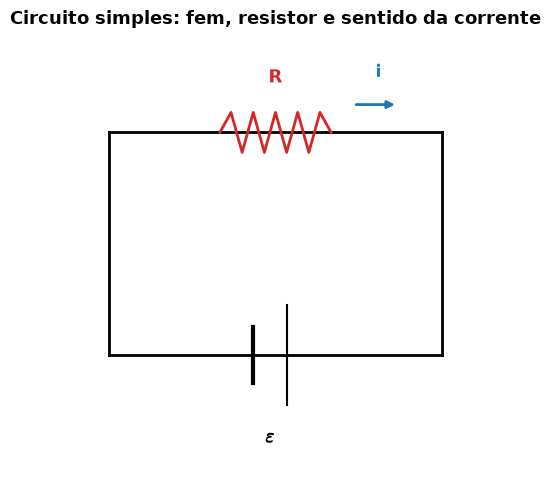

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))

# --- Diagrama de circuito simples: bateria + resistor em malha ---
ax.plot([0, 0], [0, 2], color="k", lw=2)       # fio esquerdo
ax.plot([0, 3], [2, 2], color="k", lw=2)       # fio superior
ax.plot([3, 3], [2, 0], color="k", lw=2)       # fio direito
ax.plot([3, 0], [0, 0], color="k", lw=2)       # fio inferior (terá a bateria)

# símbolo da bateria no fio inferior (duas linhas paralelas, uma longa uma curta)
ax.plot([1.3, 1.3], [-0.25, 0.25], color="k", lw=3)
ax.plot([1.6, 1.6], [-0.45, 0.45], color="k", lw=1.5)
ax.text(1.45, -0.8, r"$\varepsilon$", ha="center", fontsize=13)

# resistor em zigue-zague no fio superior
xz = np.linspace(1.0, 2.0, 11)
yz = 2 + 0.18 * np.array([0, 1, -1, 1, -1, 1, -1, 1, -1, 1, 0])
ax.plot(xz, yz, color=COR_DESTAQUE, lw=2)
ax.text(1.5, 2.45, "R", color=COR_DESTAQUE, ha="center", fontsize=13, fontweight="bold")

# seta indicando sentido da corrente
ax.annotate("", xy=(2.6, 2.25), xytext=(2.2, 2.25), arrowprops=dict(arrowstyle="-|>", color=COR_AZUL, lw=2))
ax.text(2.4, 2.5, "i", color=COR_AZUL, fontsize=12, fontweight="bold")

ax.set_xlim(-0.6, 3.6); ax.set_ylim(-1.1, 2.9)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Circuito simples: fem, resistor e sentido da corrente")
plt.tight_layout()
plt.show()


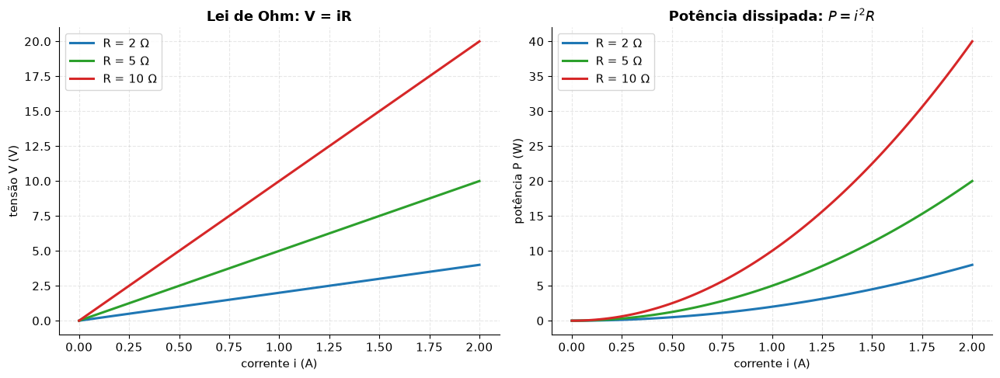

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5))

# Lei de Ohm: V = iR para diferentes R
i_arr = np.linspace(0, 2, 100)
ax = axs[0]
for R, cor in zip([2, 5, 10], [COR_AZUL, COR_OK, COR_DESTAQUE]):
    ax.plot(i_arr, i_arr * R, color=cor, label=f"R = {R} Ω")
ax.set_xlabel("corrente i (A)"); ax.set_ylabel("tensão V (V)")
ax.set_title("Lei de Ohm: V = iR")
ax.legend()

# Potência dissipada P = i^2 R
ax = axs[1]
for R, cor in zip([2, 5, 10], [COR_AZUL, COR_OK, COR_DESTAQUE]):
    ax.plot(i_arr, i_arr**2 * R, color=cor, label=f"R = {R} Ω")
ax.set_xlabel("corrente i (A)"); ax.set_ylabel("potência P (W)")
ax.set_title(r"Potência dissipada: $P=i^2R$")
ax.legend()

plt.tight_layout()
plt.show()


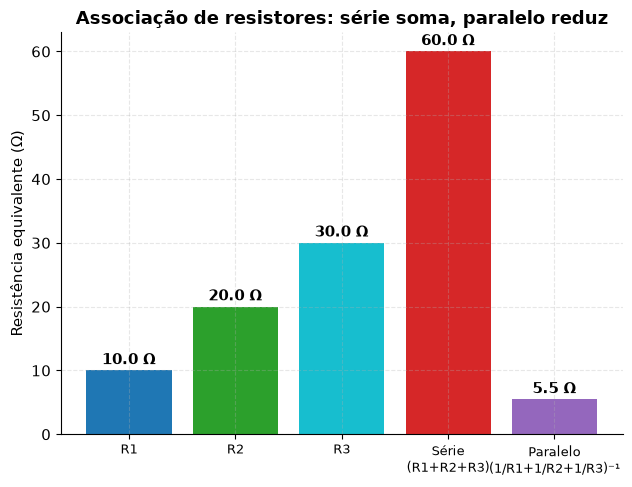

In [12]:
# Resistores em série vs. paralelo
R1, R2, R3 = 10.0, 20.0, 30.0
R_serie = R1 + R2 + R3
R_paralelo = 1 / (1/R1 + 1/R2 + 1/R3)

fig, ax = plt.subplots(figsize=(6.5, 5))
categorias = ["R1", "R2", "R3", "Série\n(R1+R2+R3)", "Paralelo\n(1/R1+1/R2+1/R3)⁻¹"]
valores = [R1, R2, R3, R_serie, R_paralelo]
cores = [COR_AZUL, COR_OK, COR_CIANO, COR_DESTAQUE, COR_ROXO]
ax.bar(categorias, valores, color=cores)
for i, v in enumerate(valores):
    ax.text(i, v + 1, f"{v:.1f} Ω", ha="center", fontweight="bold")
ax.set_ylabel("Resistência equivalente (Ω)")
ax.set_title("Associação de resistores: série soma, paralelo reduz")
plt.xticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()


> **Intuição física:** em **série**, a corrente é obrigada a passar por todos os resistores — cada um soma seu "obstáculo", e $R_{eq}$ só cresce. Em **paralelo**, a corrente tem vários caminhos para escolher — mais caminhos significam menos resistência total, por isso $R_{eq}$ é sempre menor que o menor resistor individual.

## Parte II — Magnetismo e Ondas Eletromagnéticas

<a id="sec6"></a>
## 6. Campo magnético e forças magnéticas

Diferente do campo elétrico, o campo magnético $\vec B$ não exerce força sobre cargas em repouso. A **força de Lorentz** (parte magnética) age apenas sobre cargas em movimento:

$$\vec F = q\,\vec v \times \vec B$$

Como a força é sempre perpendicular à velocidade, ela **não realiza trabalho** — apenas muda a direção do movimento, nunca a velocidade escalar. Se uma carga entra perpendicularmente num campo $\vec B$ uniforme, o resultado é um **movimento circular uniforme** (movimento ciclotrônico), com a força magnética fazendo o papel de força centrípeta:

$$qvB = \frac{mv^2}{r} \quad\Rightarrow\quad r = \frac{mv}{qB}, \qquad \omega_c = \frac{qB}{m}$$

> **Intuição física:** $\vec v\times\vec B$ é sempre perpendicular tanto a $\vec v$ quanto a $\vec B$ — por isso a força magnética "empurra de lado", nunca para frente ou para trás. É exatamente esse empurrão lateral constante que curva a trajetória em um círculo.

In [13]:
# Animação: carga positiva em movimento circular (ciclotron) num campo B uniforme saindo da página
q_ciclo = 1.0
m_ciclo = 1.0
B_ciclo = 1.0
v0 = 2.0
r_ciclo = m_ciclo * v0 / (q_ciclo * B_ciclo)
omega_ciclo = q_ciclo * B_ciclo / m_ciclo

t_ciclo = np.linspace(0, 2 * np.pi / omega_ciclo, 45)
xc = r_ciclo * np.sin(omega_ciclo * t_ciclo)
yc = r_ciclo * np.cos(omega_ciclo * t_ciclo) - r_ciclo

fig, ax = plt.subplots(figsize=(6.5, 6.5), dpi=75)
# pontos representando B saindo da página
xg, yg = np.meshgrid(np.linspace(-2.2, 2.2, 9), np.linspace(-2.2 * 2, 0.4, 9))
ax.scatter(xg, yg, marker=".", color="gray", s=20, alpha=0.6, zorder=1)

ax.plot(xc, yc, color="lightgray", lw=1.2, zorder=2)
ponto, = ax.plot([], [], "o", color=COR_DESTAQUE, ms=12, zorder=5)
seta_v = ax.annotate("", xy=(0, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=COR_AZUL, lw=2.5))
seta_f = ax.annotate("", xy=(0, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=COR_OK, lw=2.5))
txt = ax.text(-2.1, 0.25, "", fontsize=10)

ax.set_xlim(-2.3, 2.3); ax.set_ylim(-2.3 * 2 + 0.3, 0.6)
ax.set_aspect("equal")
ax.set_title("Movimento ciclotrônico: $\\vec F = q\\vec v\\times\\vec B$ (B saindo da página)")
ax.set_xlabel("x"); ax.set_ylabel("y")

def init():
    ponto.set_data([], [])
    return ponto,

def animar(i):
    x, y = xc[i], yc[i]
    ponto.set_data([x], [y])
    # velocidade tangencial
    vx = r_ciclo * omega_ciclo * np.cos(omega_ciclo * t_ciclo[i])
    vy = -r_ciclo * omega_ciclo * np.sin(omega_ciclo * t_ciclo[i])
    vnorm = np.hypot(vx, vy)
    seta_v.set_position((x, y))
    seta_v.xy = (x + 0.5 * vx / vnorm, y + 0.5 * vy / vnorm)
    # força centrípeta aponta para o centro (0, -r_ciclo)
    fx, fy = -x, -(y - (-r_ciclo))
    fnorm = np.hypot(fx, fy)
    seta_f.set_position((x, y))
    seta_f.xy = (x + 0.5 * fx / fnorm, y + 0.5 * fy / fnorm)
    txt.set_text("azul: velocidade v\nverde: força magnética F (centrípeta)")
    return ponto, seta_v, seta_f, txt

anim_ciclo = animation.FuncAnimation(fig, animar, init_func=init, frames=len(t_ciclo),
                                      interval=40, blit=False)
plt.tight_layout()
plt.close(fig)
HTML(anim_ciclo.to_jshtml())


<a id="sec7"></a>
## 7. Fontes de campo magnético

A **lei de Biot-Savart** descreve como um elemento de corrente $I\,d\vec l$ cria um campo magnético infinitesimal:

$$d\vec B = \frac{\mu_0}{4\pi}\frac{I\,d\vec l \times \hat r}{r^2}$$

Integrando essa lei para geometrias simples, obtemos resultados clássicos:

**Fio retilíneo infinito** (campo circula em torno do fio, módulo decai com $1/r$):

$$B(r) = \frac{\mu_0 I}{2\pi r}$$

**Espira circular / solenoide**: o campo no eixo e ao redor da espira tem a mesma "forma" do campo de um ímã de barra (dipolo magnético) — linhas que saem de um polo, dão a volta e entram pelo outro.

> **Intuição física:** aponte o polegar da mão direita na direção da corrente; os dedos se curvam na direção de $\vec B$ — essa é a "regra da mão direita", e ela está por trás de ambos os resultados acima.

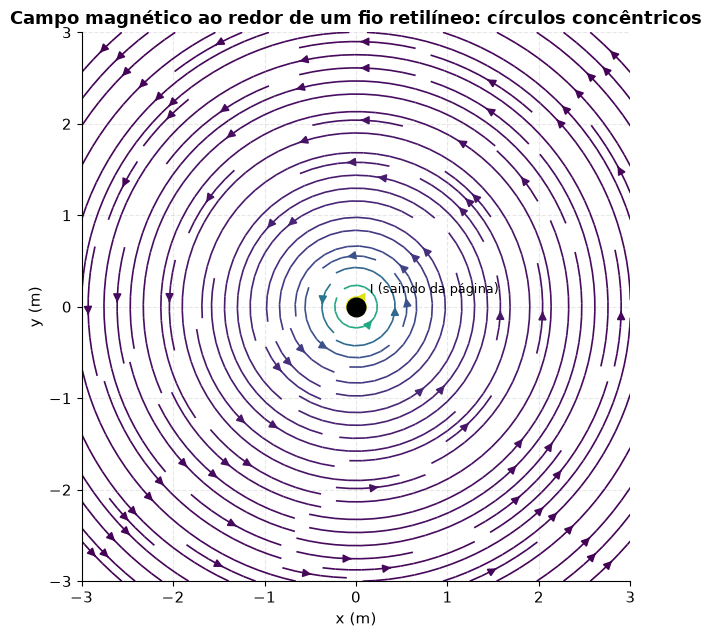

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
I_fio = 5.0
Xw, Yw = np.meshgrid(np.linspace(-3, 3, 220), np.linspace(-3, 3, 220))
r2 = Xw**2 + Yw**2 + 0.08**2
Bx = -mu0 * I_fio / (2 * np.pi * r2) * Yw
By = mu0 * I_fio / (2 * np.pi * r2) * Xw
Bmag = np.hypot(Bx, By)

ax.streamplot(Xw, Yw, Bx, By, color=Bmag, cmap="viridis", density=1.4, linewidth=1.2, arrowsize=1.2)
ax.scatter([0], [0], s=180, color="k", zorder=5)
ax.text(0.15, 0.15, "I (saindo da página)", fontsize=9)
ax.set_title("Campo magnético ao redor de um fio retilíneo: círculos concêntricos")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


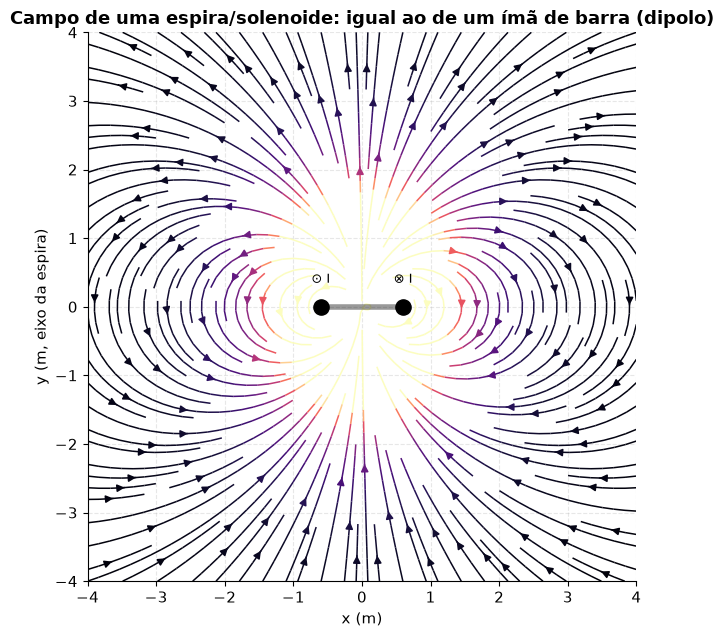

In [15]:
# Campo tipo dipolo magnético de uma espira / solenoide, no plano que contém o eixo
m_dip = 3.0  # momento de dipolo magnético (arbitrário, fins didáticos)
Xd, Yd = np.meshgrid(np.linspace(-4, 4, 260), np.linspace(-4, 4, 260))
rr = np.sqrt(Xd**2 + Yd**2) + 1e-9
Bx_d = (mu0 * m_dip / (4 * np.pi)) * (3 * Xd * Yd) / rr**5
By_d = (mu0 * m_dip / (4 * np.pi)) * (3 * Yd**2 - rr**2) / rr**5
Bmag_d = np.hypot(Bx_d, By_d)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.streamplot(Xd, Yd, Bx_d, By_d, color=Bmag_d, cmap="magma", density=1.6,
              linewidth=1.1, arrowsize=1.1, norm=plt.Normalize(0, np.percentile(Bmag_d, 90)))

# representa a espira (vista de perfil) como dois pontos: corrente saindo/entrando da página
ax.scatter([-0.6, 0.6], [0, 0], s=120, color="k", zorder=5)
ax.text(-0.6, 0.35, "⊙ I", ha="center", fontsize=9)
ax.text(0.6, 0.35, "⊗ I", ha="center", fontsize=9)
ax.plot([-0.6, 0.6], [0, 0], color="k", lw=4, alpha=0.4, zorder=4)

ax.set_title("Campo de uma espira/solenoide: igual ao de um ímã de barra (dipolo)")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m, eixo da espira)")
ax.set_aspect("equal")
ax.set_xlim(-4, 4); ax.set_ylim(-4, 4)
plt.tight_layout()
plt.show()


> **Intuição física:** perto da espira o campo "dá a volta" saindo de um lado e entrando no outro — exatamente como as linhas de campo de um ímã de barra saem do polo norte e entram no polo sul. Essa semelhança não é coincidência: um ímã permanente nada mais é do que a soma de incontáveis "espiras de corrente" microscópicas alinhadas nos átomos do material.

<a id="sec8"></a>
## 8. Indução eletromagnética e corrente de deslocamento

A **lei de Faraday** diz que uma variação do fluxo magnético através de um circuito induz uma força eletromotriz:

$$\varepsilon = -\frac{d\Phi_B}{dt}, \qquad \Phi_B = \int \vec B\cdot d\vec A$$

O sinal negativo é a **lei de Lenz**: a corrente induzida sempre flui num sentido que *se opõe* à variação de fluxo que a criou (a natureza "resiste" à mudança).

Maxwell percebeu que, para manter a consistência das equações do eletromagnetismo (especialmente em circuitos com capacitores, onde a corrente de condução é interrompida), era necessário somar um termo adicional — a **corrente de deslocamento** $I_d = \varepsilon_0\,d\Phi_E/dt$ — à lei de Ampère. Fisicamente, um campo elétrico variável no tempo também gera campo magnético, assim como uma corrente de condução.

> **Intuição física:** abaixo, uma espira quadrada atravessa uma região onde há campo magnético (como entrar e sair de um ímã). Enquanto ela **entra**, o fluxo cresce e a fem induzida tem um sinal; enquanto ela **sai**, o fluxo decresce e a fem troca de sinal — esse é o coração da lei de Lenz.

In [16]:
# Animação: espira quadrada atravessando uma região de campo magnético uniforme
L_espira = 1.0           # lado da espira
B0 = 1.0                 # intensidade do campo na região
x_regiao = (2.0, 4.0)    # região do campo em x
x_loop_vals = np.linspace(0, 6, 55)

def fluxo(xl):
    # sobreposição entre a espira [xl - L/2, xl + L/2] e a regiao de campo [x_regiao]
    esq = max(xl - L_espira/2, x_regiao[0])
    dir_ = min(xl + L_espira/2, x_regiao[1])
    largura_sobreposta = max(0.0, dir_ - esq)
    return B0 * largura_sobreposta * L_espira

Phi_vals = np.array([fluxo(xl) for xl in x_loop_vals])
dt_frame = x_loop_vals[1] - x_loop_vals[0]
emf_vals = -np.gradient(Phi_vals, dt_frame)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.6), dpi=70)

ax0 = axs[0]
ax0.add_patch(Rectangle((x_regiao[0], -1.5), x_regiao[1]-x_regiao[0], 3.0, color=COR_AZUL, alpha=0.18))
ax0.text(np.mean(x_regiao), 1.6, "região com B (⊗ para dentro da página)", color=COR_AZUL, ha="center", fontsize=8)
loop_patch = Rectangle((0 - L_espira/2, -L_espira/2), L_espira, L_espira, fill=False, edgecolor=COR_DESTAQUE, lw=2.5)
ax0.add_patch(loop_patch)
ax0.set_xlim(0, 6); ax0.set_ylim(-2, 2)
ax0.set_aspect("equal")
ax0.set_title("Espira atravessando o campo")
ax0.set_xlabel("posição x")

ax1 = axs[1]
line_phi, = ax1.plot([], [], color=COR_OK, lw=2.5)
pt_phi, = ax1.plot([], [], "o", color=COR_OK, ms=8)
ax1.set_xlim(0, 6); ax1.set_ylim(min(Phi_vals)-0.1, max(Phi_vals)*1.2 + 0.1)
ax1.set_title(r"Fluxo $\Phi_B(t)$")
ax1.set_xlabel("posição x (~tempo)")

ax2 = axs[2]
line_emf, = ax2.plot([], [], color=COR_DESTAQUE, lw=2.5)
pt_emf, = ax2.plot([], [], "o", color=COR_DESTAQUE, ms=8)
ax2.axhline(0, color="gray", lw=1)
ax2.set_xlim(0, 6); ax2.set_ylim(min(emf_vals)*1.2 - 0.1, max(emf_vals)*1.2 + 0.1)
ax2.set_title(r"fem induzida $\varepsilon=-d\Phi_B/dt$ (lei de Lenz)")
ax2.set_xlabel("posição x (~tempo)")

def init():
    loop_patch.set_xy((0 - L_espira/2, -L_espira/2))
    line_phi.set_data([], []); pt_phi.set_data([], [])
    line_emf.set_data([], []); pt_emf.set_data([], [])
    return loop_patch, line_phi, pt_phi, line_emf, pt_emf

def animar(i):
    xl = x_loop_vals[i]
    loop_patch.set_xy((xl - L_espira/2, -L_espira/2))
    line_phi.set_data(x_loop_vals[:i+1], Phi_vals[:i+1])
    pt_phi.set_data([xl], [Phi_vals[i]])
    line_emf.set_data(x_loop_vals[:i+1], emf_vals[:i+1])
    pt_emf.set_data([xl], [emf_vals[i]])
    return loop_patch, line_phi, pt_phi, line_emf, pt_emf

anim_ind = animation.FuncAnimation(fig, animar, init_func=init, frames=len(x_loop_vals),
                                    interval=35, blit=False)
plt.tight_layout()
plt.close(fig)
HTML(anim_ind.to_jshtml())


> **Lei de Lenz em ação:** repare que $\varepsilon$ é positivo enquanto o fluxo está **aumentando** (espira entrando no campo) e negativo enquanto o fluxo está **diminuindo** (espira saindo) — a corrente induzida sempre tenta manter o fluxo como estava, opondo-se à mudança.

<a id="sec9"></a>
## 9. Indutância

Um **indutor** se opõe a variações de corrente através dele, criando uma fem auto-induzida

$$\varepsilon = -L\frac{di}{dt}$$

onde $L$ é a **indutância** (henries, H). Num circuito RL com uma bateria de tensão $V$, a corrente cresce exponencialmente ao ligar a chave:

$$i(t) = \frac{V}{R}\left(1 - e^{-tR/L}\right)$$

e decai exponencialmente ao desligar a fonte (circuito RL em curto):

$$i(t) = \frac{V}{R}\,e^{-tR/L}$$

com constante de tempo $\tau = L/R$. A energia armazenada no campo magnético do indutor é

$$U = \frac{1}{2}Li^2$$

> **Intuição física:** o indutor é o "análogo elétrico" da inércia mecânica — assim como uma massa resiste a mudanças bruscas de velocidade, o indutor resiste a mudanças bruscas de corrente, suavizando degraus abruptos de tensão em variações graduais de corrente.

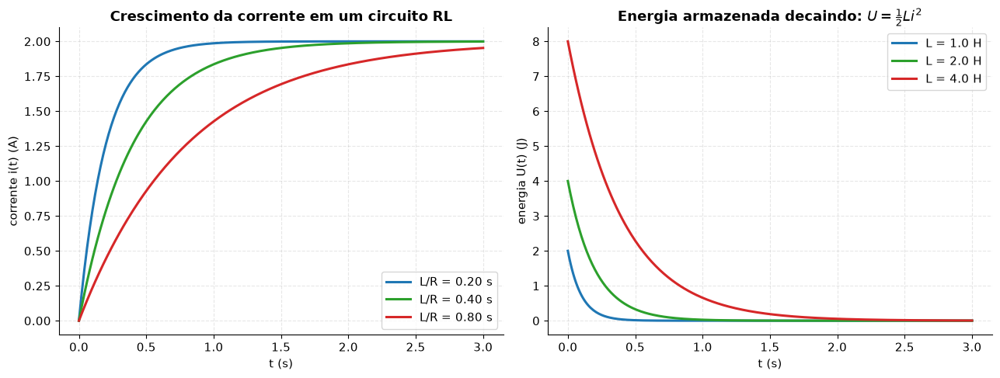

In [17]:
V_rl = 10.0
R_rl = 5.0
fig, axs = plt.subplots(1, 2, figsize=(13, 5))

ax = axs[0]
t_rl = np.linspace(0, 3, 300)
for L_rl, cor in zip([1.0, 2.0, 4.0], [COR_AZUL, COR_OK, COR_DESTAQUE]):
    tau_rl = L_rl / R_rl
    i_cresce = (V_rl / R_rl) * (1 - np.exp(-t_rl / tau_rl))
    ax.plot(t_rl, i_cresce, color=cor, label=fr"L/R = {tau_rl:.2f} s")
ax.set_xlabel("t (s)"); ax.set_ylabel("corrente i(t) (A)")
ax.set_title("Crescimento da corrente em um circuito RL")
ax.legend()

ax = axs[1]
for L_rl, cor in zip([1.0, 2.0, 4.0], [COR_AZUL, COR_OK, COR_DESTAQUE]):
    tau_rl = L_rl / R_rl
    i_max = V_rl / R_rl
    i_decai = i_max * np.exp(-t_rl / tau_rl)
    U_rl = 0.5 * L_rl * i_decai**2
    ax.plot(t_rl, U_rl, color=cor, label=fr"L = {L_rl} H")
ax.set_xlabel("t (s)"); ax.set_ylabel("energia U(t) (J)")
ax.set_title(r"Energia armazenada decaindo: $U=\frac{1}{2}Li^2$")
ax.legend()

plt.tight_layout()
plt.show()


<a id="sec10"></a>
## 10. Ondas eletromagnéticas

As **equações de Maxwell** (lei de Gauss elétrica, lei de Gauss magnética, lei de Faraday e lei de Ampère-Maxwell), tomadas em conjunto no vácuo, implicam que perturbações de $\vec E$ e $\vec B$ se propagam como **ondas** com velocidade

$$c = \frac{1}{\sqrt{\mu_0\varepsilon_0}} \approx 3\times10^8\ \text{m/s}$$

Uma onda eletromagnética plana simples, propagando-se em $+z$, tem a forma

$$E_x(z,t) = E_0\cos(kz - \omega t), \qquad B_y(z,t) = B_0\cos(kz - \omega t), \qquad E_0 = cB_0$$

Ou seja: $\vec E$, $\vec B$ e a direção de propagação $\hat z$ formam um **trio mutuamente perpendicular**, e os dois campos oscilam **em fase** um com o outro.

> **Intuição física:** um campo elétrico variável gera (pela lei de Ampère-Maxwell) um campo magnético variável, que por sua vez gera (pela lei de Faraday) um campo elétrico variável, e assim por diante — a onda eletromagnética é essa "dança" de autossustentação entre $\vec E$ e $\vec B$, sem precisar de nenhum meio material para se propagar.

In [18]:
# Animação 3D: E (plano xz) e B (plano yz) oscilando perpendiculares, propagando em z
z_arr = np.linspace(0, 4 * np.pi, 200)
k_onda = 1.0
E0, B0 = 1.0, 1.0
n_frames = 36
omega_frames = np.linspace(0, 4 * np.pi, n_frames)

fig = plt.figure(figsize=(8, 6.5), dpi=75)
ax3d = fig.add_subplot(111, projection="3d")

linha_E, = ax3d.plot([], [], [], color=COR_DESTAQUE, lw=2.5, label="E (x)")
linha_B, = ax3d.plot([], [], [], color=COR_AZUL, lw=2.5, label="B (y)")
ax3d.plot(z_arr, 0*z_arr, 0*z_arr, color="gray", lw=1, linestyle=":")  # eixo de propagação

ax3d.set_xlim(0, 4*np.pi); ax3d.set_ylim(-1.5, 1.5); ax3d.set_zlim(-1.5, 1.5)
ax3d.set_xlabel("z (propagação)"); ax3d.set_ylabel("E_x"); ax3d.set_zlabel("B_y")
ax3d.set_title("Onda eletromagnética: E e B oscilando em fase, perpendiculares entre si")
ax3d.legend(loc="upper right")

def init():
    linha_E.set_data([], []); linha_E.set_3d_properties([])
    linha_B.set_data([], []); linha_B.set_3d_properties([])
    return linha_E, linha_B

def animar(i):
    wt = omega_frames[i]
    Ex = E0 * np.cos(k_onda * z_arr - wt)
    By = B0 * np.cos(k_onda * z_arr - wt)
    linha_E.set_data(z_arr, Ex); linha_E.set_3d_properties(np.zeros_like(z_arr))
    linha_B.set_data(z_arr, np.zeros_like(z_arr)); linha_B.set_3d_properties(By)
    return linha_E, linha_B

anim_onda = animation.FuncAnimation(fig, animar, init_func=init, frames=n_frames,
                                     interval=60, blit=False)
plt.close(fig)
HTML(anim_onda.to_jshtml())


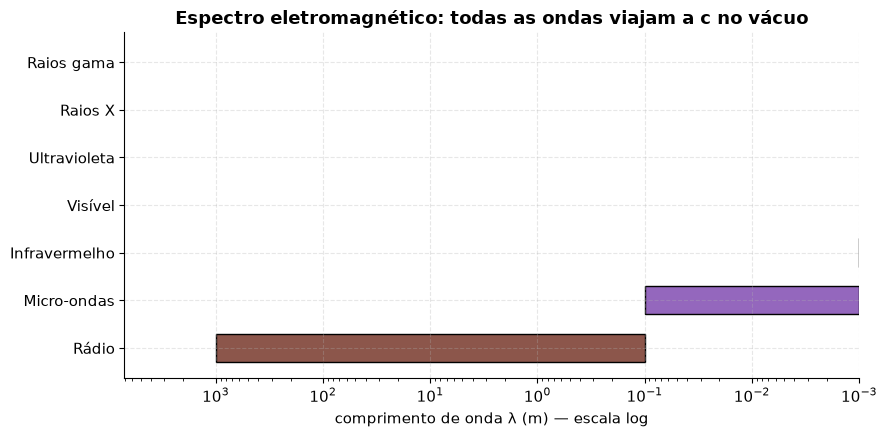

Luz visível: aprox. 400-700 nm. c = 2.998e+08 m/s para TODAS as faixas do espectro.


In [19]:
# Espectro eletromagnético (escala logarítmica de comprimento de onda)
faixas = [
    ("Rádio",        1e3,  1e-1,  "#8c564b"),
    ("Micro-ondas",  1e-1, 1e-3,  "#9467bd"),
    ("Infravermelho",1e-3, 7e-7,  COR_DESTAQUE),
    ("Visível",      7e-7, 4e-7,  COR_LARANJA),
    ("Ultravioleta", 4e-7, 1e-8,  COR_AZUL),
    ("Raios X",      1e-8, 1e-11, COR_CIANO),
    ("Raios gama",   1e-11,1e-14, COR_OK),
]

fig, ax = plt.subplots(figsize=(9, 4.5))
for i, (nome, lam_max, lam_min, cor) in enumerate(faixas):
    ax.barh(nome, lam_max - lam_min, left=lam_min, color=cor, edgecolor="k", height=0.6)

ax.set_xscale("log")
ax.invert_xaxis()  # comprimento de onda diminuindo da esquerda p/ direita (frequência aumentando)
ax.set_xlabel("comprimento de onda λ (m) — escala log")
ax.set_title("Espectro eletromagnético: todas as ondas viajam a c no vácuo")
ax.axvline(5.5e-7, color="k", linestyle=":", lw=1)
plt.tight_layout()
plt.show()

print(f"Luz visível: aprox. 400-700 nm. c = {c_luz:.3e} m/s para TODAS as faixas do espectro.")


---

### Encerramento

Com isso cobrimos os dez pilares conceituais de Física III: dos campos estáticos criados por cargas paradas (Coulomb, Gauss, potencial, capacitância) aos circuitos de corrente contínua, passando pelo magnetismo gerado por cargas em movimento (força de Lorentz, Biot-Savart), até a indução — a ponte entre eletricidade e magnetismo que culmina nas ondas eletromagnéticas de Maxwell, unificando luz, rádio, raios X e tudo mais num único fenômeno.

Revise as animações e os campos vetoriais sempre que uma fórmula parecer abstrata demais: por trás de cada uma delas há uma imagem geométrica simples esperando para ser vista.